# Dar_045 - UV: spectrum, uncertainty, time and polar-map support

## Questions
- Which wavelengths/bands have supported daily values, and which contain zeros or missing bins?
- How much of a supported band is in a model-assisted spectral region? What uncertainty assumptions matter?
- How do the **same series** vary by UTC month, quarter, four-month term, half-year, year, two-year window and DJF/MAM/JJA/SON calendar window?
- Do fixed June-October comparisons differ from partial-year summaries?
- How much native southern LAMP map support survives quality, SNR and exposure checks? Did stride-4 screening distort regional support?
- What follows for environmental assessment and proposed requirements - and what remains Unknown?

This is a dedicated subject analysis, not a renamed Dar_044 extract. All selected SEE spectra and all native pixels of the 20 selected LAMP maps are analysed; display thumbnails alone are downsampled. LAMP is a historical cumulative map, not a new monthly irradiance history. Calendar seasons are labels, not lunar climate seasons. No Stage 5 integration occurs.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'darrel stuff/EDA').is_dir())
sys.path.insert(0,str(root/'darrel stuff/EDA/Moon/Stage3_Requirements'))
from stage3_uv_eda import execute

## Run the reproducible subject study
Raw files are receipt/hash checked. The full run keeps inputs, tables, plots and source contracts in its own completed provenance directory. `--sample` is only a bounded validation mode, not the full subject study.

In [2]:
folder, findings = execute()
print(folder)
display(findings)

Reading complete SEE spectra


C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\EDA\Moon\Stage3_Requirements\stage3_uv_eda.py:88: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  monthly = spectra.groupby(spectra.index.strftime('%Y-%m')).median().stack(dropna=False).rename('median_positive_daily_flux_W_m2_nm').reset_index()


Scanning native LAMP pixels in bounded windows


Native LAMP complete: long


Native LAMP complete: lya


Native LAMP complete: off


Native LAMP complete: on


{
  "subject": "solar_uv",
  "sample": false,
  "tables": {
    "band_daily_context": 6030,
    "spectral_support": 195,
    "monthly_spectral_profile": 7995,
    "calendar_context": 1384,
    "matched_June_October_years": 54,
    "lamp_native_statistics": 256,
    "lamp_native_quality": 59,
    "lamp_albedo_histograms": 32000,
    "lamp_time_applicability": 20,
    "crosscheck_screening": 2,
    "crosscheck_native_vs_stride4": 32,
    "cross_product_applicability": 2,
    "crosscheck_existing_sunlight_uv_proxy": 21,
    "stage4_uv_proposals": 6
  },
  "bands": [
    {
      "band": "EGS_subband_50_115",
      "recorded_days": 1206,
      "supported_days": 1206,
      "median_supported_integral": 0.0027727964347832312,
      "median_assisted_fraction": 0.007992792102739382
    },
    {
      "band": "EUV_27_115",
      "recorded_days": 1206,
      "supported_days": 139,
      "median_supported_integral": 0.004678315328192184,
      "median_assisted_fraction": 0.00455342518139708
    },

C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\data\processed\analysis\subject_uv\20261110T171338818645Z_f97fcb


{'subject': 'solar_uv',
 'sample': False,
 'tables': {'band_daily_context': 6030,
  'spectral_support': 195,
  'monthly_spectral_profile': 7995,
  'calendar_context': 1384,
  'matched_June_October_years': 54,
  'lamp_native_statistics': 256,
  'lamp_native_quality': 59,
  'lamp_albedo_histograms': 32000,
  'lamp_time_applicability': 20,
  'crosscheck_screening': 2,
  'crosscheck_native_vs_stride4': 32,
  'cross_product_applicability': 2,
  'crosscheck_existing_sunlight_uv_proxy': 21,
  'stage4_uv_proposals': 6},
 'bands': [{'band': 'EGS_subband_50_115',
   'recorded_days': 1206,
   'supported_days': 1206,
   'median_supported_integral': 0.0027727964347832312,
   'median_assisted_fraction': 0.007992792102739382},
  {'band': 'EUV_27_115',
   'recorded_days': 1206,
   'supported_days': 139,
   'median_supported_integral': 0.004678315328192184,
   'median_assisted_fraction': 0.00455342518139708},
  {'band': 'FUV_115_180',
   'recorded_days': 1206,
   'supported_days': 1206,
   'median_supp

## 1. Spectral support and uncertainty
Band integrals require every declared 1-nm bin to pass the explicit positive/finite screen. Unsupported wide bands remain missing; a differently named subband is not a substitute. Error-sum and independence-RSS are different assumptions, not an established confidence interval. Product-description model partitions are not per-record measured/modelled flags.

In [3]:
display(pd.read_csv(folder/'band_support_summary.csv'))
support = pd.read_csv(folder/'spectral_support.csv')
display(support.loc[support.wavelength_nm.isin([.5,26.5,27.5,50.5,114.5,121.5,128.5,179.5,189.5,194.5])])

,band,recorded_days,supported_days,median_supported_integral,median_assisted_fraction
0,EGS_subband_50_115,1206,1206,0.002773,0.007993
1,EUV_27_115,1206,139,0.004678,0.004553
2,FUV_115_180,1206,1206,0.024210,0.030861
3,UV_180_190,1206,1206,0.026019,0.000000
4,XUV_0_27,1206,727,0.002871,1.000000


,wavelength_nm,recorded_days,positive_supported_days,zero_flux_days,negative_flux_days,nonfinite_flux_days,model_assisted_partition,inside_documented_0_190nm,median_positive_flux_W_m2_nm,median_fractional_error
0,0.5,1206,727,479,0,0,True,True,0.000013,0.191444
26,26.5,1206,727,479,0,0,True,True,0.000072,0.191444
27,27.5,1206,1206,0,0,0,False,True,0.000049,0.514215
50,50.5,1206,1206,0,0,0,False,True,0.000023,0.228391
114,114.5,1206,1206,0,0,0,True,True,0.000021,0.300000
121,121.5,1206,1206,0,0,0,False,True,0.007407,0.391206
128,128.5,1206,1206,0,0,0,True,True,0.000019,0.037554
179,179.5,1206,1206,0,0,0,False,True,0.001574,0.260636
189,189.5,1206,1206,0,0,0,False,True,0.002755,0.344134
194,194.5,1206,0,1206,0,0,False,False,NaN,NaN


## 2. Timestamp-based comparisons
Half-year means H1/H2; two-year means non-overlapping even-year pairs anchored at 2000. Four-month terms are Jan?Apr/May?Aug/Sep?Dec. DJF uses the year of January/February. Coverage denominators include complete calendar windows and expose partial edge periods. Historical SOLSTICE and contemporary SEE remain distinct instruments/epochs; daily means cannot reveal flare peaks.

In [4]:
calendar = pd.read_csv(folder/'calendar_context.csv')
display(calendar.groupby('period_kind').agg(rows=('period','size'), valid_days=('valid_days','sum')))
display(calendar.loc[calendar.series_id.eq('SEE_v012_FUV_115_180') & calendar.period_kind.isin(['half_year','year','two_year'])])
display(pd.read_csv(folder/'matched_June_October_years.csv').query("series_id == 'SEE_v012_FUV_115_180'"))

,rows,valid_days
period_kind,,
calendar_season,206,15944
four_month_term,157,15944
half_year,110,15944
month,609,15944
quarter,211,15944
two_year,35,15944
year,56,15944


,series_id,period_kind,period,period_start_utc,period_stop_exclusive_utc,expected_calendar_days,days_inside_observed_source_span,partial_source_span_period,recorded_days,valid_days,...,median_of_daily_values,p05_of_daily_values,p95_of_daily_values,minimum_daily_value,maximum_daily_value,maximum_of_reported_daily_maxima,longest_absent_date_run_days,longest_unsupported_date_run_days,interpretation,reported_valid_seconds
259,SEE_v012_FUV_115_180,half_year,2023-H1,2023-01-01T00:00:00+00:00,2023-07-01T00:00:00+00:00,181,30,True,30,30,...,0.026251,0.024681,0.027225,0.024523,0.027491,0.027491,151,151,"UTC calendar comparison, not lunar seasons, el...",NaN
260,SEE_v012_FUV_115_180,half_year,2023-H2,2023-07-01T00:00:00+00:00,2024-01-01T00:00:00+00:00,184,184,False,183,183,...,0.025869,0.023978,0.026807,0.023227,0.027570,0.027570,1,1,"UTC calendar comparison, not lunar seasons, el...",NaN
261,SEE_v012_FUV_115_180,half_year,2024-H1,2024-01-01T00:00:00+00:00,2024-07-01T00:00:00+00:00,182,182,False,169,169,...,0.024891,0.023683,0.026332,0.023485,0.027177,0.027177,13,13,"UTC calendar comparison, not lunar seasons, el...",NaN
262,SEE_v012_FUV_115_180,half_year,2024-H2,2024-07-01T00:00:00+00:00,2025-01-01T00:00:00+00:00,184,184,False,182,182,...,0.025648,0.024272,0.027407,0.023448,0.028301,0.028301,2,2,"UTC calendar comparison, not lunar seasons, el...",NaN
263,SEE_v012_FUV_115_180,half_year,2025-H1,2025-01-01T00:00:00+00:00,2025-07-01T00:00:00+00:00,181,181,False,172,172,...,0.023702,0.022365,0.025943,0.021723,0.037397,0.037397,9,9,"UTC calendar comparison, not lunar seasons, el...",NaN
264,SEE_v012_FUV_115_180,half_year,2025-H2,2025-07-01T00:00:00+00:00,2026-01-01T00:00:00+00:00,184,184,False,182,182,...,0.023211,0.021722,0.024724,0.021085,0.025776,0.025776,1,1,"UTC calendar comparison, not lunar seasons, el...",NaN
265,SEE_v012_FUV_115_180,half_year,2026-H1,2026-01-01T00:00:00+00:00,2026-07-01T00:00:00+00:00,181,181,False,167,167,...,0.022235,0.021105,0.023618,0.020352,0.034523,0.034523,13,13,"UTC calendar comparison, not lunar seasons, el...",NaN
266,SEE_v012_FUV_115_180,half_year,2026-H2,2026-07-01T00:00:00+00:00,2027-01-01T00:00:00+00:00,184,123,True,121,121,...,0.021874,0.020690,0.023639,0.020214,0.024319,0.024319,61,61,"UTC calendar comparison, not lunar seasons, el...",NaN
267,SEE_v012_FUV_115_180,year,2023,2023-01-01T00:00:00+00:00,2024-01-01T00:00:00+00:00,365,214,True,213,213,...,0.025892,0.024098,0.026962,0.023227,0.027570,0.027570,151,151,"UTC calendar comparison, not lunar seasons, el...",NaN
268,SEE_v012_FUV_115_180,year,2024,2024-01-01T00:00:00+00:00,2025-01-01T00:00:00+00:00,366,366,False,351,351,...,0.025265,0.023790,0.026950,0.023448,0.028301,0.028301,13,13,"UTC calendar comparison, not lunar seasons, el...",NaN


,series_id,year,months_inclusive,expected_days,recorded_days,valid_days,median_daily_value,p05_daily_value,p95_daily_value,maximum_daily_value,interpretation
8,SEE_v012_FUV_115_180,2023,06-10,153,153,153,0.026067,0.024774,0.027042,0.027570,"same calendar months, not a trend-significance..."
9,SEE_v012_FUV_115_180,2024,06-10,153,151,151,0.025923,0.024769,0.027521,0.028301,"same calendar months, not a trend-significance..."
10,SEE_v012_FUV_115_180,2025,06-10,153,151,151,0.023287,0.021891,0.024736,0.025776,"same calendar months, not a trend-significance..."
11,SEE_v012_FUV_115_180,2026,06-10,153,151,151,0.021958,0.020810,0.023632,0.024383,"same calendar months, not a trend-significance..."


## 3. Native polar-map support and regional contrasts
Statistics use bounded native-pixel windows in all four LAMP band families. `ERROR` is SNR. Counts are projected-pixel weighted, not exact spherical area. Histogram quantiles are intervals; below/above-range pixels remain counted. Quality-masked pixels are not proof of darkness, zero UV or ice. Brightness/albedo cannot be substituted for local incident irradiance.

In [5]:
quality = pd.read_csv(folder/'lamp_native_quality.csv')
display(quality.loc[quality.region.eq('south_polar_domain')])
stats = pd.read_csv(folder/'lamp_native_statistics.csv')
display(stats.loc[stats.quantity.eq('ALBEDO') & stats.cohort.eq('joint_quality_supported')])
display(pd.read_csv(folder/'lamp_time_applicability.csv').drop_duplicates(['label_start_time_utc','label_stop_time_utc']))

,band,region,domain_pixels,quality_zero_pixels,positive_exposure_pixels,snr_ge3_pixels,joint_support_pixels,supported_fraction,sample,scope,quality_flag,flag_pixels
0,long,south_polar_domain,5023277.0,2342568.0,5021404.0,2346215.0,2342338.0,0.466297,False,native pixel counts; quality masks are not env...,NaN,NaN
15,lya,south_polar_domain,5023277.0,4968408.0,5019806.0,4974728.0,4966208.0,0.988639,False,native pixel counts; quality masks are not env...,NaN,NaN
29,off,south_polar_domain,5023277.0,191062.0,5015383.0,190552.0,190552.0,0.037934,False,native pixel counts; quality masks are not env...,NaN,NaN
44,on,south_polar_domain,5023277.0,1451971.0,5018758.0,1451644.0,1451644.0,0.288983,False,native pixel counts; quality masks are not env...,NaN,NaN


,band,region,quantity,cohort,finite_pixels,mean,standard_deviation,minimum,maximum,p50_hist_lower,...,p95_hist_lower,p95_hist_upper,below_histogram_range,above_histogram_range,quantile_semantics,unit,wavelength_min_nm,wavelength_max_nm,pixel_weighting,spatial_support
1,long,south_polar_domain,ALBEDO,joint_quality_supported,2342338,0.038275,0.016272,0.002008,0.565671,0.035,...,0.070,0.071,0,0,"histogram intervals, not exact pixel quantiles...",dimensionless,129.57,189.57,"equal projected native pixel, not exact surfac...","bounding-box pixel centres, not certified cand..."
9,long,A3CLR22_10_Leibnitz_Beta_Plateau,ALBEDO,joint_quality_supported,666,0.059825,0.018944,0.018045,0.111685,0.058,...,0.090,0.091,0,0,"histogram intervals, not exact pixel quantiles...",dimensionless,129.57,189.57,"equal projected native pixel, not exact surfac...","bounding-box pixel centres, not certified cand..."
17,long,A3CLR22_11_Malapert_Massif,ALBEDO,joint_quality_supported,2110,0.051373,0.024531,0.012791,0.565671,0.048,...,0.082,0.083,0,0,"histogram intervals, not exact pixel quantiles...",dimensionless,129.57,189.57,"equal projected native pixel, not exact surfac...","bounding-box pixel centres, not certified cand..."
25,long,A3CLR22_12_deGerlache_Kocher_Massif,ALBEDO,joint_quality_supported,3632,0.042074,0.016232,0.009181,0.098689,0.039,...,0.074,0.075,0,0,"histogram intervals, not exact pixel quantiles...",dimensionless,129.57,189.57,"equal projected native pixel, not exact surfac...","bounding-box pixel centres, not certified cand..."
33,long,A3CLR22_2_Haworth,ALBEDO,joint_quality_supported,7371,0.040985,0.016067,0.008093,0.104829,0.038,...,0.071,0.072,0,0,"histogram intervals, not exact pixel quantiles...",dimensionless,129.57,189.57,"equal projected native pixel, not exact surfac...","bounding-box pixel centres, not certified cand..."
41,long,A3CLR22_3_Faustini_Rim_A,ALBEDO,joint_quality_supported,4975,0.036724,0.015637,0.008151,0.102825,0.033,...,0.067,0.068,0,0,"histogram intervals, not exact pixel quantiles...",dimensionless,129.57,189.57,"equal projected native pixel, not exact surfac...","bounding-box pixel centres, not certified cand..."
49,long,A3CLR22_4_deGerlache_Rim_2,ALBEDO,joint_quality_supported,5901,0.034016,0.014694,0.007011,0.105955,0.031,...,0.061,0.062,0,0,"histogram intervals, not exact pixel quantiles...",dimensionless,129.57,189.57,"equal projected native pixel, not exact surfac...","bounding-box pixel centres, not certified cand..."
57,long,A3CLR22_5_Connecting_Ridge_Extension,ALBEDO,joint_quality_supported,5172,0.038059,0.016590,0.006162,0.102519,0.034,...,0.070,0.071,0,0,"histogram intervals, not exact pixel quantiles...",dimensionless,129.57,189.57,"equal projected native pixel, not exact surfac...","bounding-box pixel centres, not certified cand..."
65,lya,south_polar_domain,ALBEDO,joint_quality_supported,4966208,0.037232,0.099488,0.004195,119.842430,0.036,...,0.051,0.052,0,27,"histogram intervals, not exact pixel quantiles...",dimensionless,119.57,125.57,"equal projected native pixel, not exact surfac...","bounding-box pixel centres, not certified cand..."
73,lya,A3CLR22_10_Leibnitz_Beta_Plateau,ALBEDO,joint_quality_supported,4206,0.041193,0.012981,0.011996,0.114780,0.039,...,0.064,0.065,0,0,"histogram intervals, not exact pixel quantiles...",dimensionless,119.57,125.57,"equal projected native pixel, not exact surfac...","bounding-box pixel centres, not certified cand..."


,dataset,time_basis,label_start_time_utc,label_stop_time_utc,calendar_binning_applicable,reason
0,LAMP_long_ALBEDO,historical cumulative map,2009-09-01T00:00:00,2010-10-01T00:00:00,False,label acquisition interval is not a pixel-leve...


## 4. Cross-check existing EDA and draft Stage 4 implications
Common-band results must agree with Dar_044; native-pixel support may differ from its systematic stride-4 sample. Those differences are a scope/aliasing issue, not automatically a contradiction or site-safety change. The proposed rules below are unadopted and unconsumed by the current engine.

In [6]:
display(pd.read_csv(folder/'crosscheck_screening.csv'))
display(pd.read_csv(folder/'crosscheck_native_vs_stride4.csv')[['band','region','supported_fraction','stride4_support_fraction','native_minus_stride4_percentage_points']])
display(pd.read_csv(folder/'cross_product_applicability.csv'))
display(pd.read_csv(folder/'stage4_uv_proposals.csv'))

,check,subject,paired_files,different_support_rows,maximum_absolute_difference,conclusion
0,Dar044_same_band_integrals,EUV_27_115,1206,0,9.974660e-17,same raw band/screening semantics; new subband...
1,Dar044_same_band_integrals,FUV_115_180,1206,0,9.714451e-17,same raw band/screening semantics; new subband...


,band,region,supported_fraction,stride4_support_fraction,native_minus_stride4_percentage_points
0,long,south_polar_domain,0.466297,0.465124,0.117238
1,long,A3CLR22_10_Leibnitz_Beta_Plateau,0.148363,0.152344,-0.398109
2,long,A3CLR22_11_Malapert_Massif,0.275601,0.294372,-1.877146
3,long,A3CLR22_12_deGerlache_Kocher_Massif,0.520941,0.530612,-0.967134
4,long,A3CLR22_2_Haworth,0.475548,0.450572,2.497607
5,long,A3CLR22_3_Faustini_Rim_A,0.713569,0.726190,-1.262192
6,long,A3CLR22_4_deGerlache_Rim_2,0.856583,0.840476,1.610677
7,long,A3CLR22_5_Connecting_Ridge_Extension,0.732993,0.743764,-1.077098
8,lya,south_polar_domain,0.988639,0.987669,0.097003
9,lya,A3CLR22_10_Leibnitz_Beta_Plateau,0.936957,0.937500,-0.054299


,left,right,simultaneous_overlap,reason
0,SOLSTICE,SEE,False,"historical SOLSTICE ends 2020, SEE cohort begi..."
1,SEE,LAMP,False,"LAMP maps aggregate 2009-2010 acquisition, not..."


,id,classification,title,required_inputs,current_outcome,outcome_scope_note,existing_rule_crosswalk,decision_logic,quantity,unit,applicability,limit_value,limit_state,preference_weight,status,evidence,source
0,UV-G01,evidence_guard,"Complete band, units and uncertainty support",daily spectrum and native support/quality meta...,Unknown,Unknown for local exposure; Failed only if an ...,E01 E04 E13,No zero-filled or partial spectral sum may sta...,spectral/local response-specific; see requirem...,quantity-specific,Moon mission/activity and local footprint/peri...,NaN,not_adopted,NaN,Stage 4 proposal only; not loaded by pipeline,band_daily_context.csv; spectral_support.csv; ...,provider SEE/LAMP labels and README; accepted ...
1,UV-H01,conditional_hard_constraint,Applicable crew/material UV exposure limit,"local incident spectrum, duration/activity, pr...",Unknown,Unknown,E04 E13,If applicable evaluated demand exceeds an adop...,spectral/local response-specific; see requirem...,quantity-specific,Moon mission/activity and local footprint/peri...,NaN,not_adopted,NaN,Stage 4 proposal only; not loaded by pipeline,band_daily_context.csv; spectral_support.csv; ...,provider SEE/LAMP labels and README; accepted ...
2,UV-S01,conditional_soft_preference,Lower supported operational UV burden where de...,"mandatory conditions Passed, equivalent missio...",Unknown,Unknown,E13,Preference only after all mandatory conditions...,spectral/local response-specific; see requirem...,quantity-specific,Moon mission/activity and local footprint/peri...,NaN,not_adopted,NaN,Stage 4 proposal only; not loaded by pipeline,band_daily_context.csv; spectral_support.csv; ...,provider SEE/LAMP labels and README; accepted ...
3,UV-G02,evidence_guard,LAMP albedo/brightness is not incident UV dose,"quantity/units, historical acquisition support...",Unknown,Unknown for dose,E01 E04 E13,Native reflectance/SNR/exposure context may be...,spectral/local response-specific; see requirem...,quantity-specific,Moon mission/activity and local footprint/peri...,NaN,not_adopted,NaN,Stage 4 proposal only; not loaded by pipeline,band_daily_context.csv; spectral_support.csv; ...,provider SEE/LAMP labels and README; accepted ...
4,UV-G03,evidence_guard,Explicit calendar windows and peak limitations,"UTC source dates, coverage, instrument cadence...",Unknown,Unknown for forecast or flare peak,E14 E15,DJF labels are not lunar climate seasons; dail...,spectral/local response-specific; see requirem...,quantity-specific,Moon mission/activity and local footprint/peri...,NaN,not_adopted,NaN,Stage 4 proposal only; not loaded by pipeline,band_daily_context.csv; spectral_support.csv; ...,provider SEE/LAMP labels and README; accepted ...
5,UV-G04,evidence_guard,Keep solar products and epochs distinct,instrument/version/model-assisted partition an...,Unknown,Unknown for unsupported cross-product substitu...,E15 E16,New contemporary SEE overlap does not change h...,spectral/local response-specific; see requirem...,quantity-specific,Moon mission/activity and local footprint/peri...,NaN,not_adopted,NaN,Stage 4 proposal only; not loaded by pipeline,band_daily_context.csv; spectral_support.csv; ...,provider SEE/LAMP labels and README; accepted ...


## 5. Figures
Spectral zeros, uncertainty and support must be read alongside levels. Native statistics and downsampled display maps have separate roles.

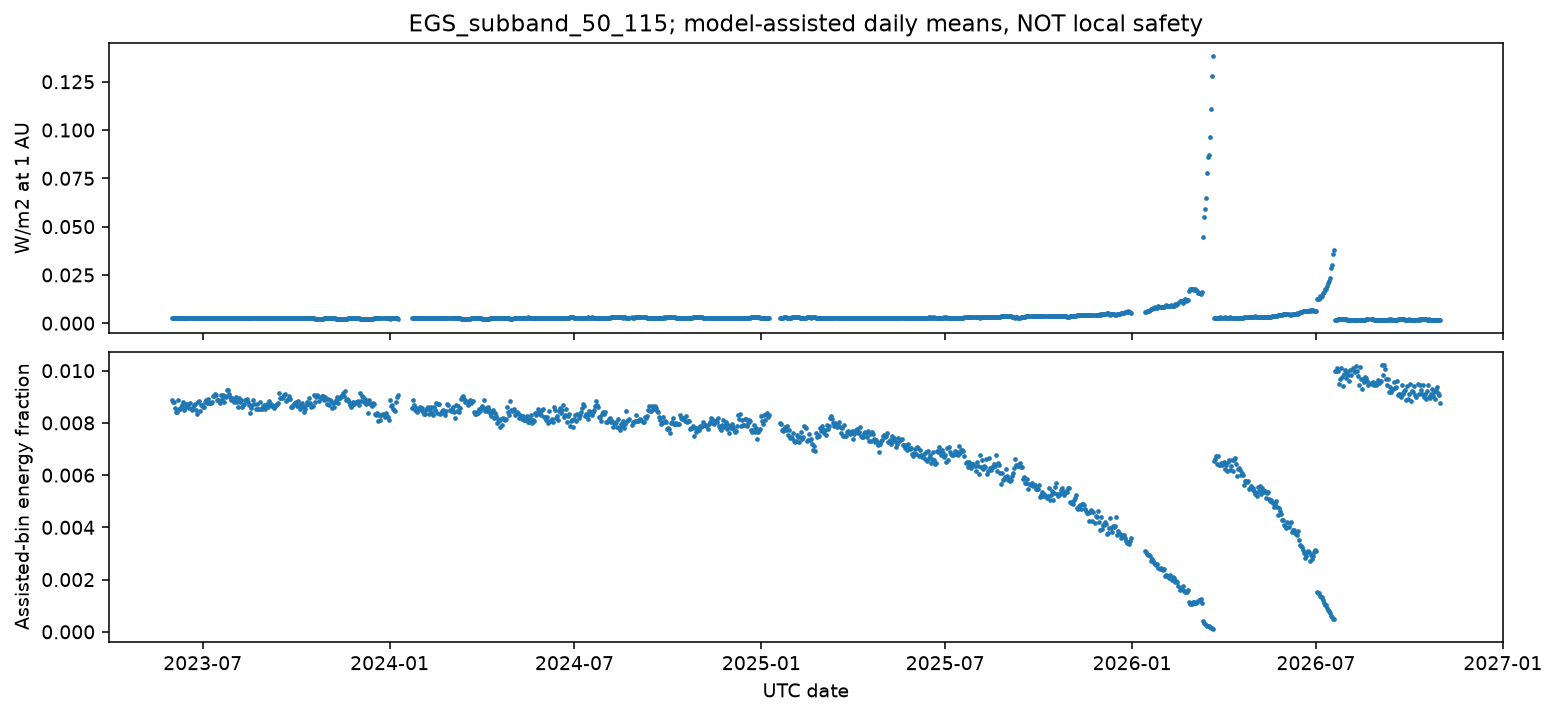

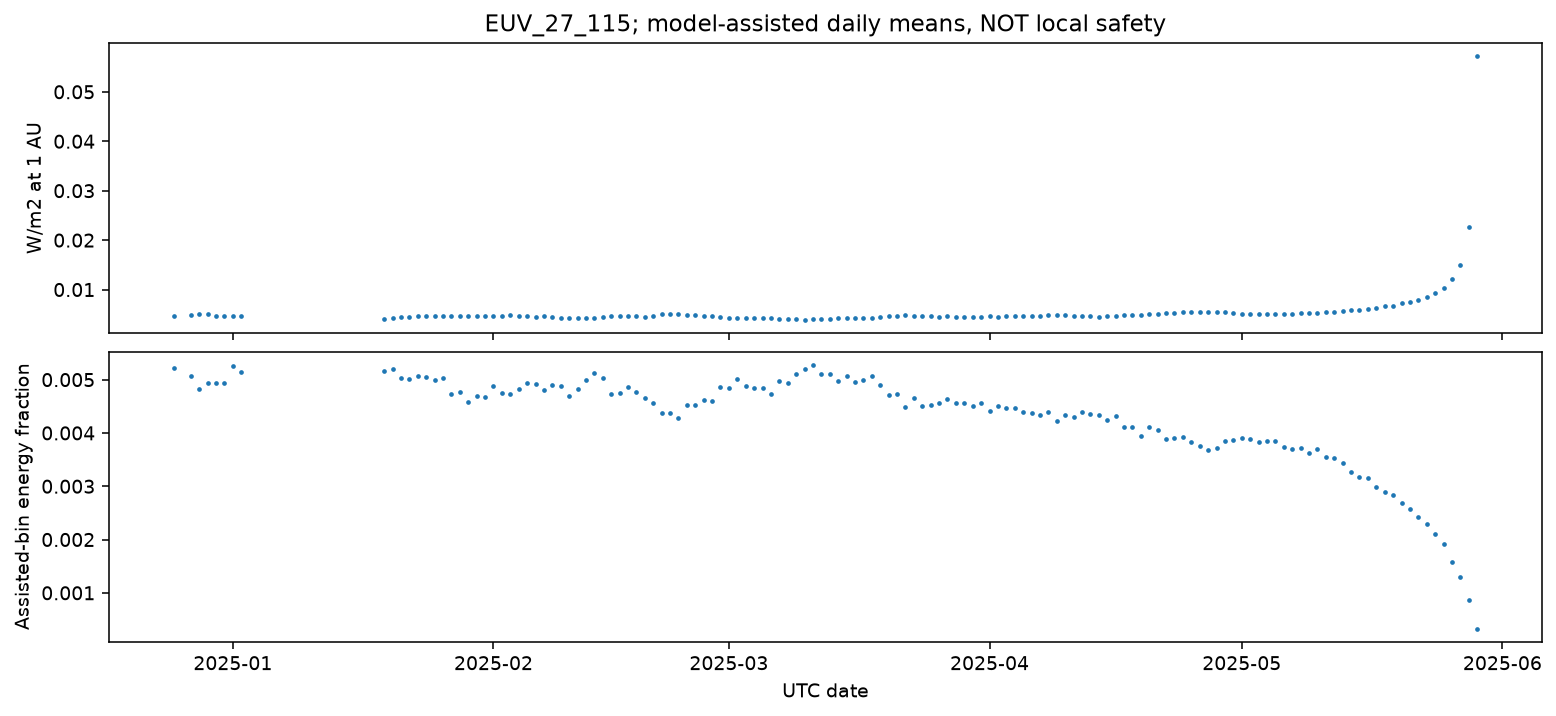

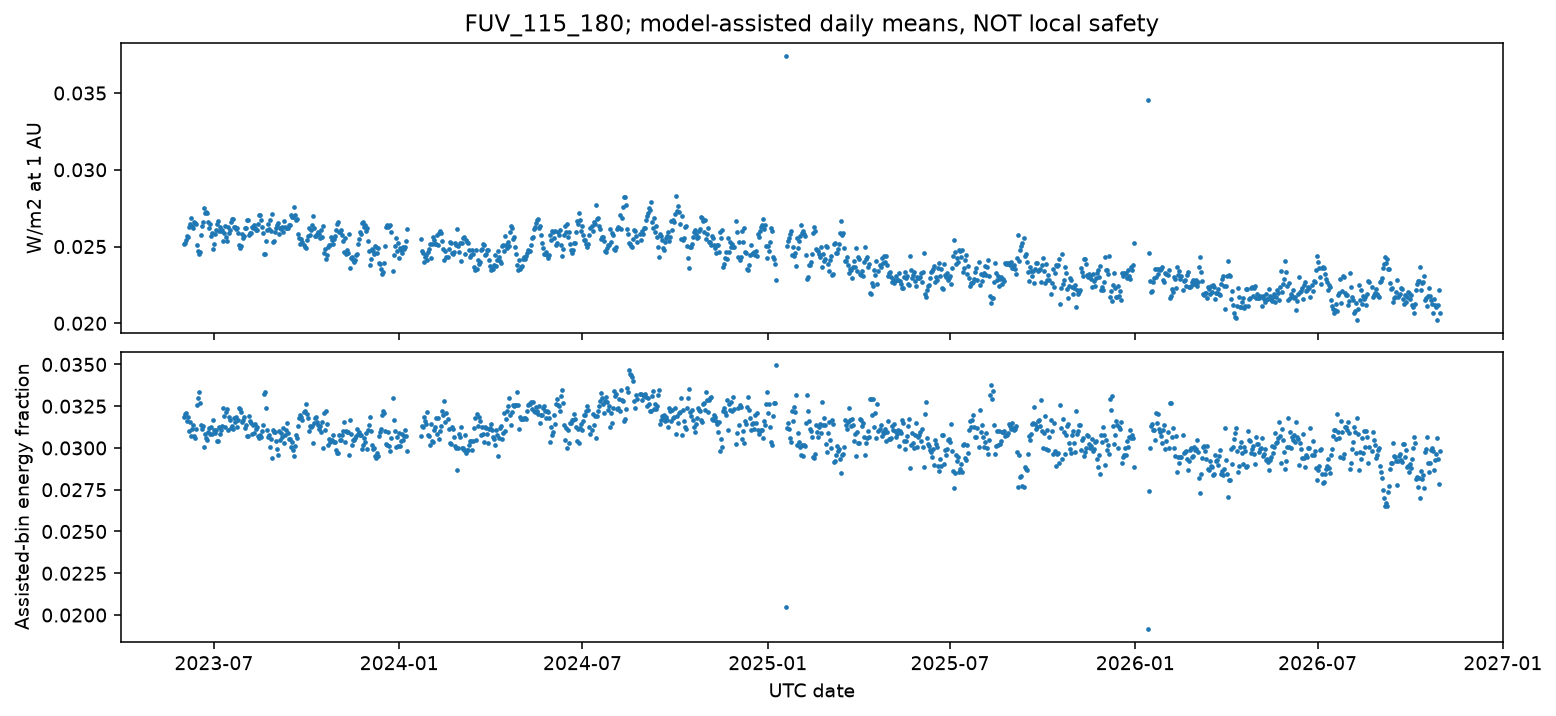

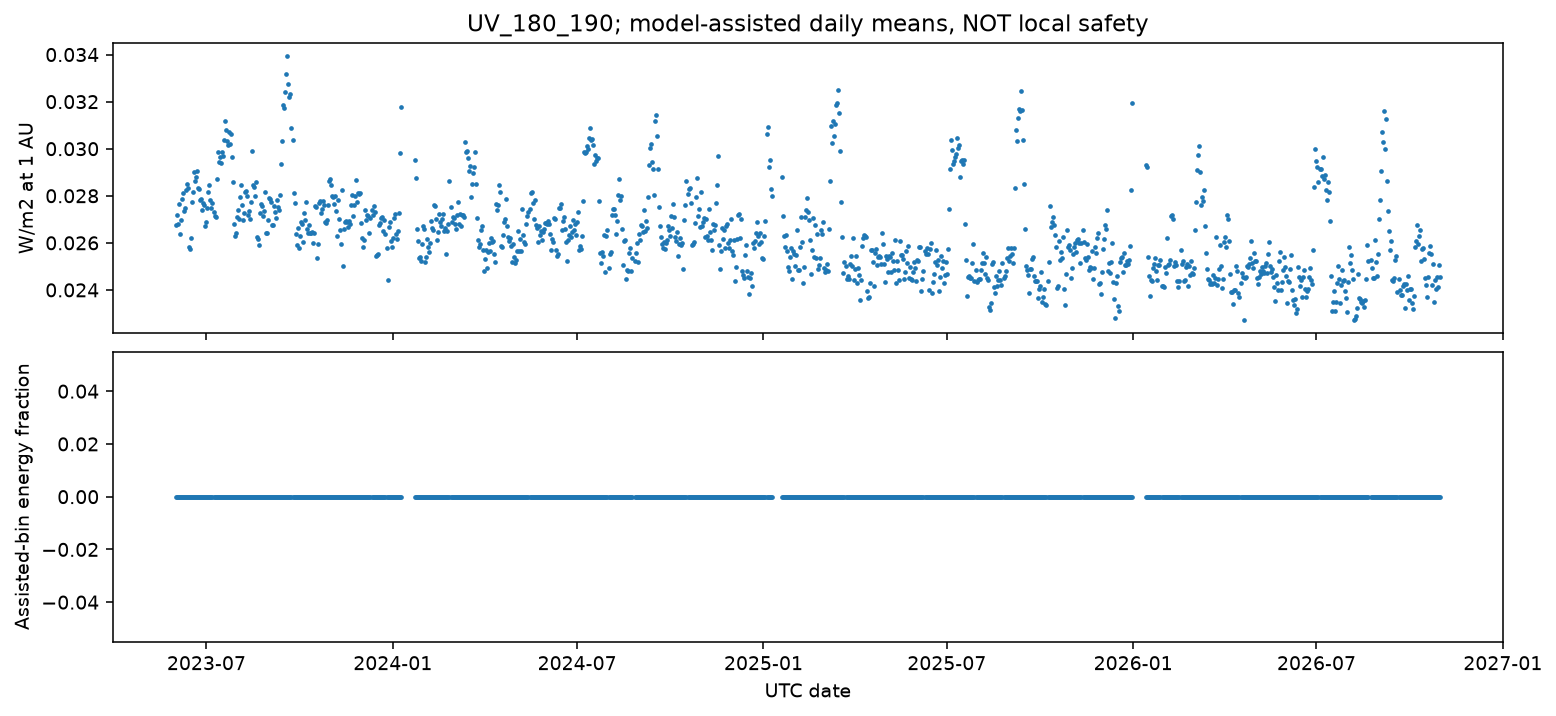

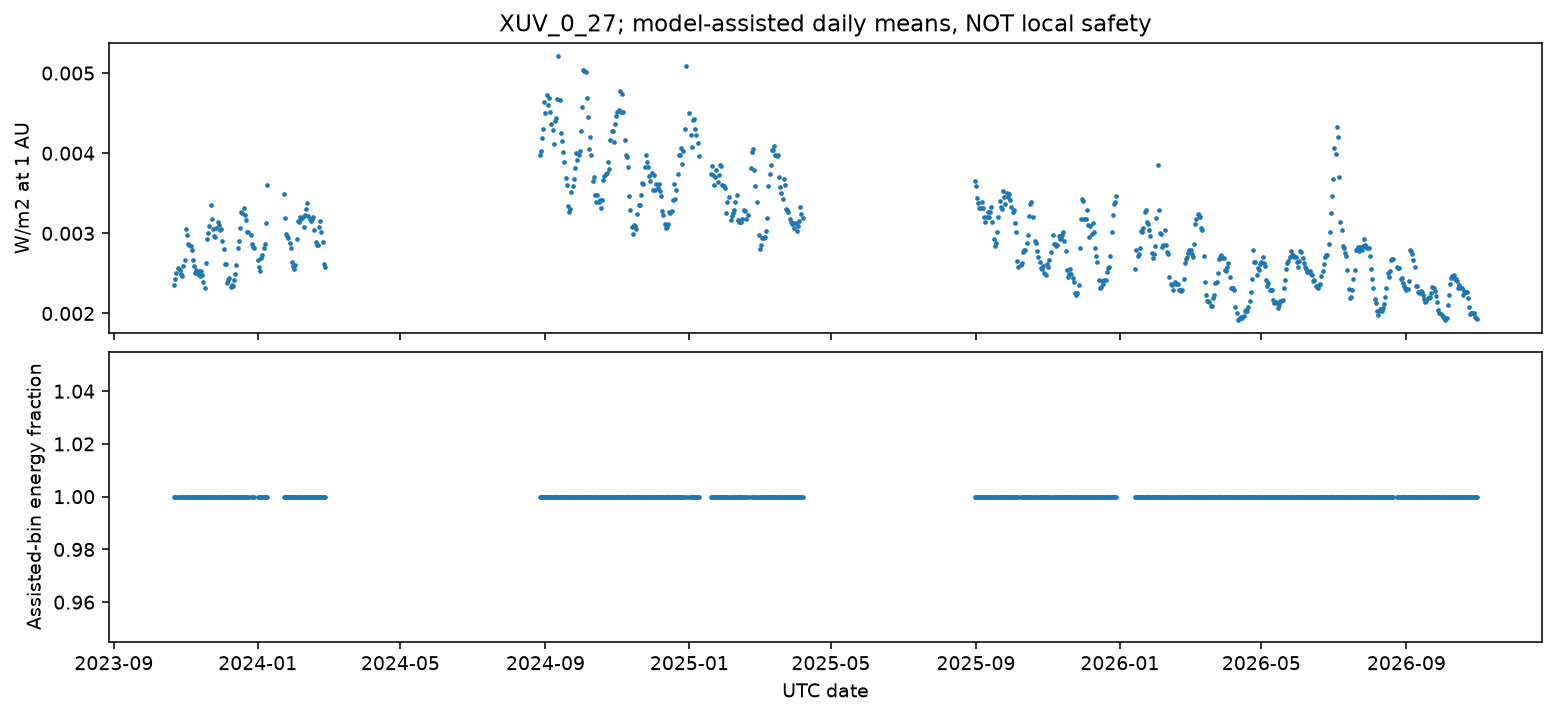

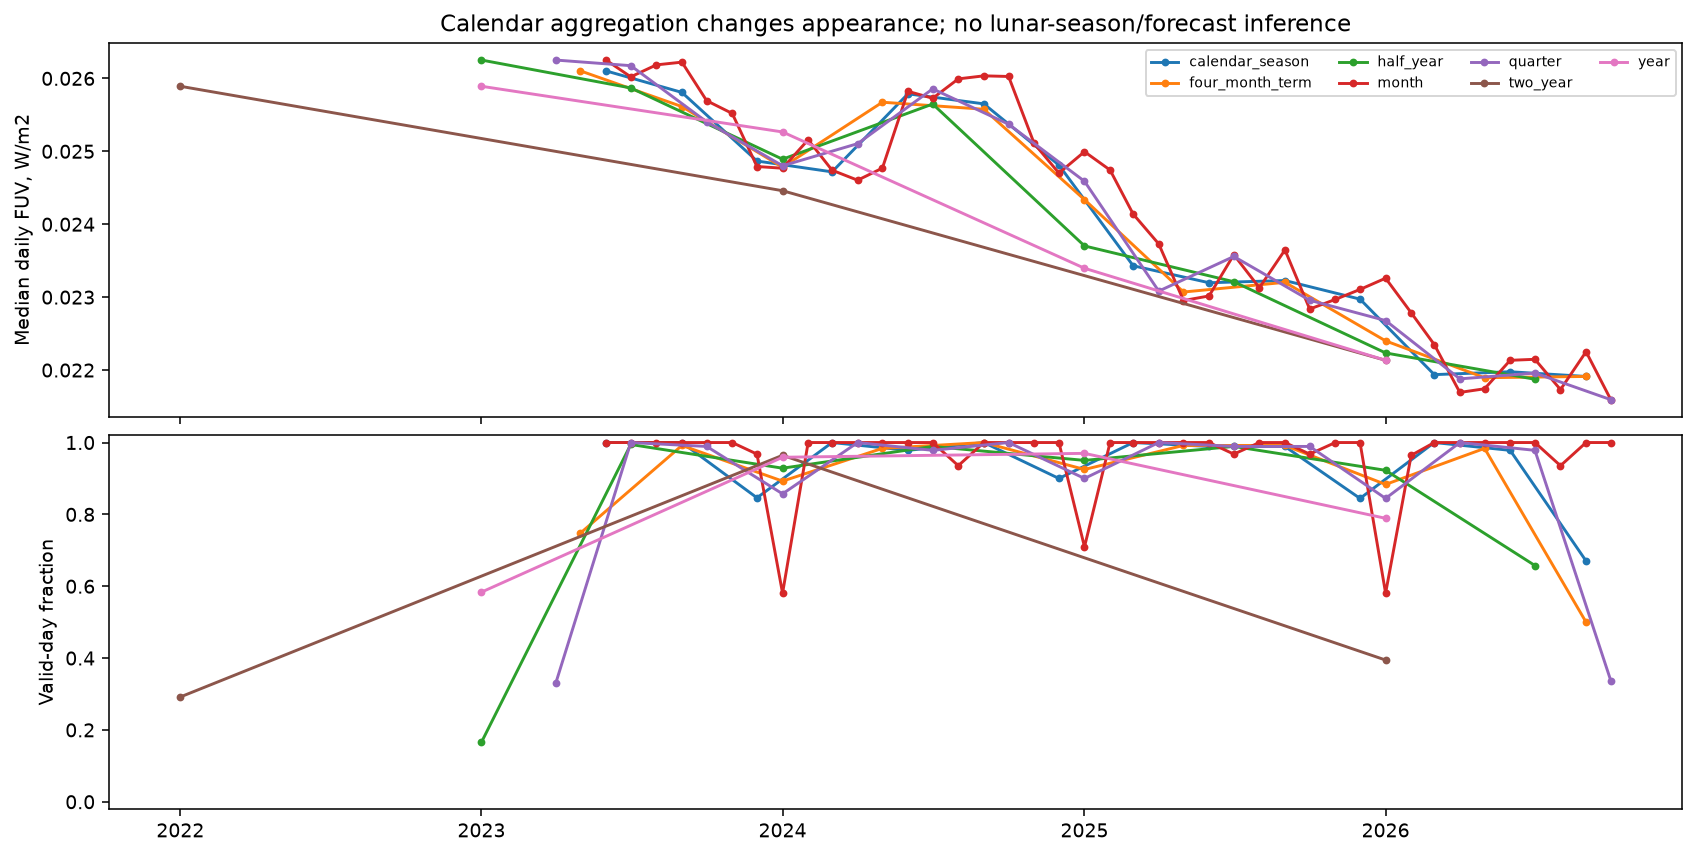

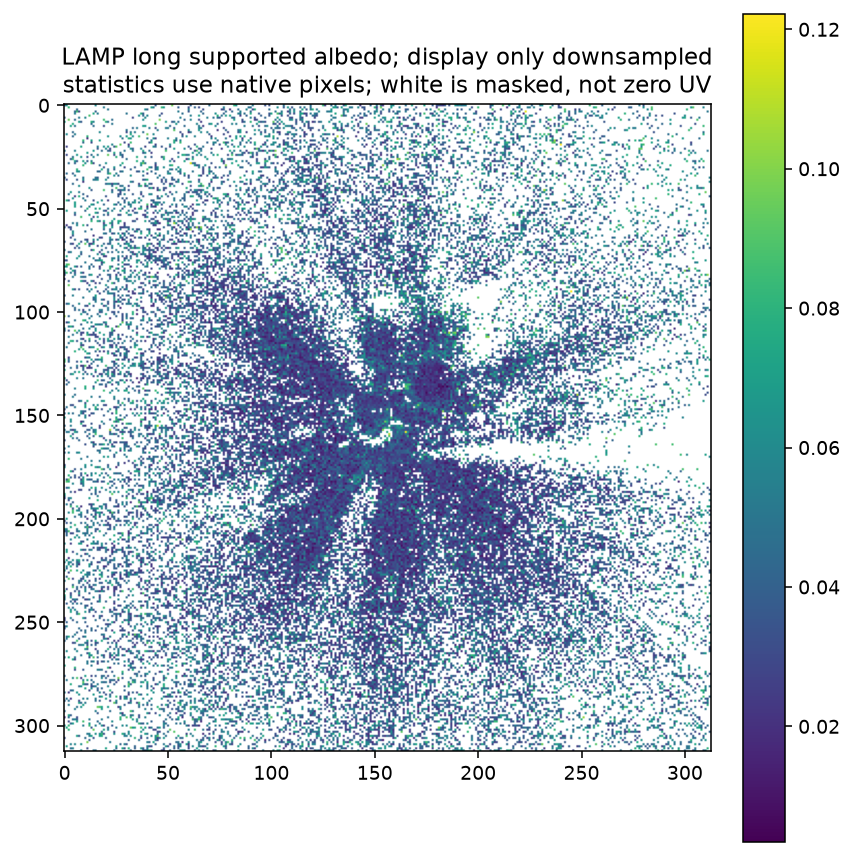

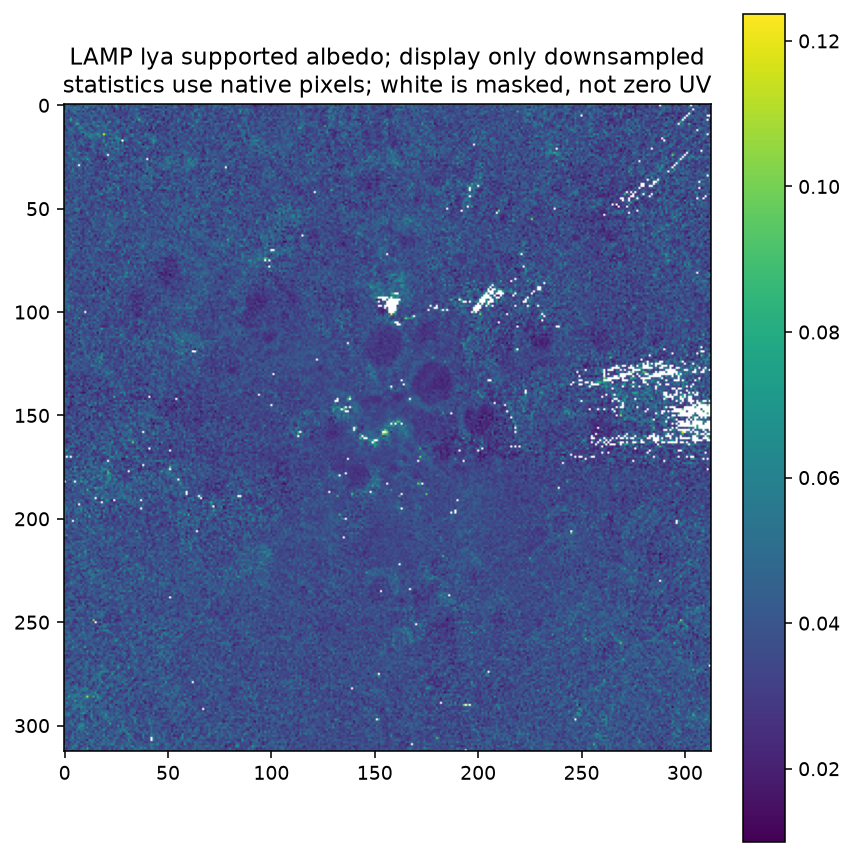

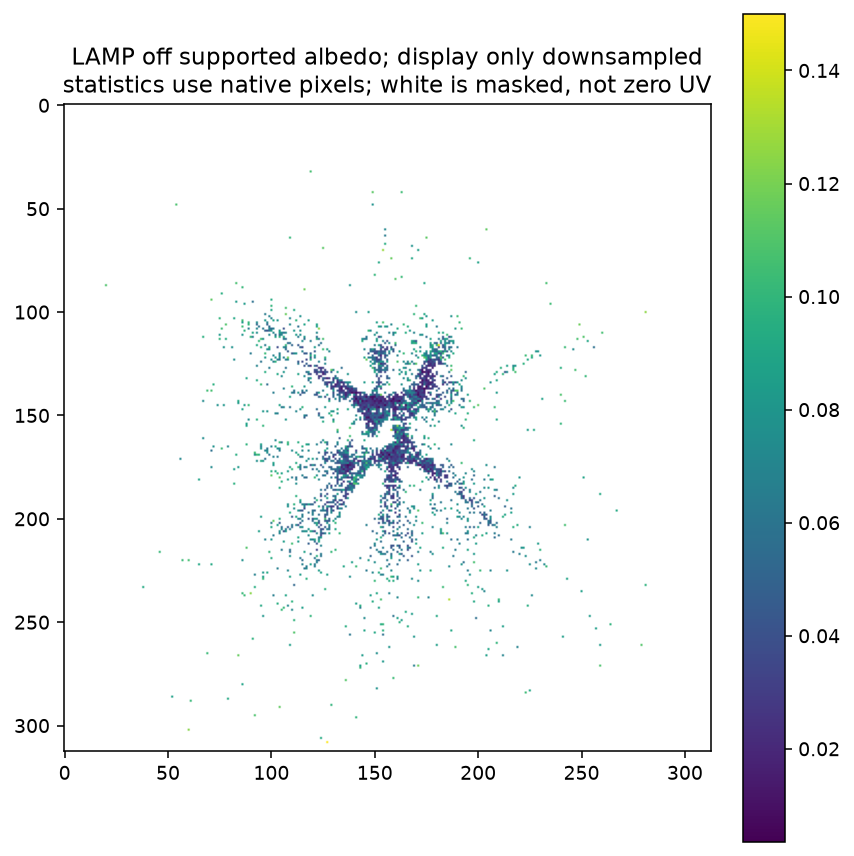

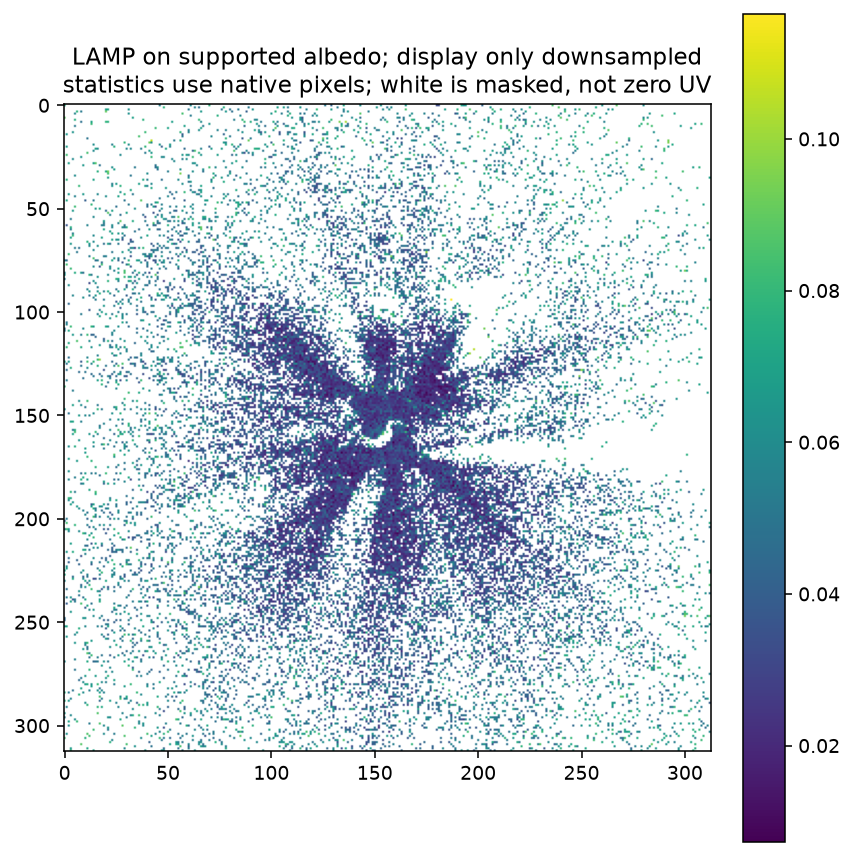

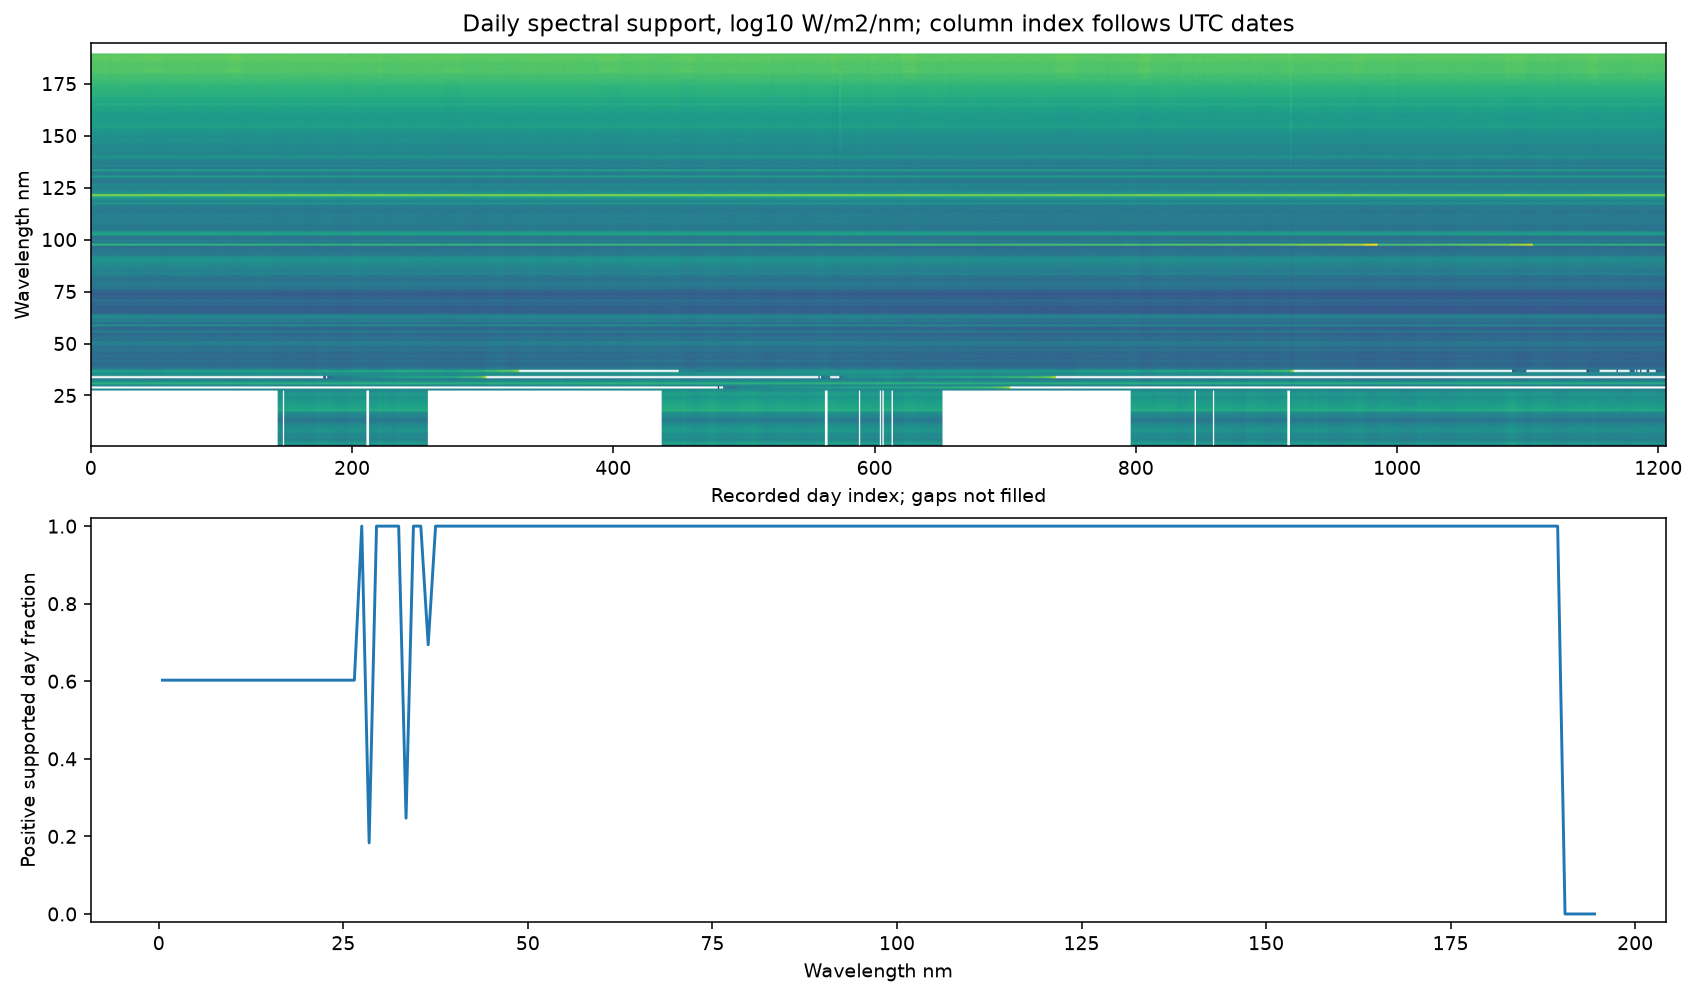

In [7]:
for path in sorted(folder.glob('*.png')):
    display(Image(filename=str(path)))

## Base conclusion and remaining evidence

The spectrum and native-pixel study can improve solar-reference variability, uncertainty and polar-map support assessment. It does **not** establish local crew/material UV dose, an automatically safe season, or operational suitability. Such claims need local geometry, activity/duration, protection, a qualified response/action model and an applicable adopted limit. Lower sunlight/UV opportunity can conflict with power needs and must not be counted twice as independent weighted evidence. The figures/tables and `findings.json` contain the executed results; no numeric safety threshold or Stage 5 source pin is changed.